In [1]:
# =====================================================
# STEP 1: IMPORT NECESSARY LIBRARIES
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

In [2]:
# =====================================================
# STEP 2: LOAD DATASET
# =====================================================

data = pd.read_csv("ecg.csv", header=None)

X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Dataset Shape:", data.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nClass Distribution:")
print(pd.Series(y).value_counts())

Dataset Shape: (4998, 141)
Features Shape: (4998, 140)
Target Shape: (4998,)

Class Distribution:
1.0    2919
0.0    2079
Name: count, dtype: int64


In [3]:
# =====================================================
# STEP 3: PREPROCESS THE DATA
# =====================================================

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define normal class
NORMAL_LABEL = 1

# Select only normal samples for training
X_train_normal = X_train[y_train == NORMAL_LABEL]

# Normalize the data
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# Reshape data for Conv1D
# (samples, timesteps, features)

X_train_normal = X_train_normal.reshape(-1, 140, 1)
X_train = X_train.reshape(-1, 140, 1)
X_test = X_test.reshape(-1, 140, 1)

print("\nNormal Training Shape:", X_train_normal.shape)
print("Testing Shape:", X_test.shape)


Normal Training Shape: (2335, 140, 1)
Testing Shape: (1000, 140, 1)


In [4]:
# =====================================================
# STEP 4: BUILD CONVOLUTIONAL AUTOENCODER
# =====================================================

input_layer = keras.Input(shape=(140, 1))

# ---------------- ENCODER ----------------

x = layers.Conv1D(
    32, kernel_size=3,
    strides=2, padding='same',
    activation='relu'
)(input_layer)

x = layers.Conv1D(
    64, kernel_size=3,
    strides=2, padding='same',
    activation='relu'
)(x)

encoded = layers.Conv1D(
    128, kernel_size=3,
    strides=2, padding='same',
    activation='relu'
)(x)


# ---------------- DECODER ----------------

x = layers.Conv1DTranspose(
    64, kernel_size=3,
    strides=2, padding='same',
    activation='relu'
)(encoded)

x = layers.Conv1DTranspose(
    32, kernel_size=3,
    strides=2, padding='same',
    activation='relu'
)(x)

x = layers.Conv1DTranspose(
    1, kernel_size=3,
    strides=2, padding='same',
    activation='linear'
)(x)

# Output length is 144, so crop to 140
decoded = layers.Cropping1D(
    cropping=(2, 2)
)(x)

# Build model
autoencoder = keras.Model(input_layer, decoded)

In [5]:
# =====================================================
# STEP 5: COMPILE THE MODEL
# =====================================================

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140, 1)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                      │ (None, 70, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 35, 64)              │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 18, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_transpose (Conv1DTranspose)   │ (None, 36, 64)              │          24,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_transpose_1 (Conv1DTranspose) │ (None, 72, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_transpose_2 (Conv1DTranspose) │ (None, 144, 1)              │              97 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ cropping1d (Cropping1D)              │ (None, 140, 1)              │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 61,953 (242.00 KB)

 Trainable params: 61,953 (242.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# =====================================================
# STEP 6: TRAIN THE MODEL
# =====================================================

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 220ms/step - loss: 0.7476 - mae: 0.5952 - val_loss: 0.3792 - val_mae: 0.4154
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.2047 - mae: 0.3068 - val_loss: 0.1732 - val_mae: 0.2650
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - loss: 0.1045 - mae: 0.2161 - val_loss: 0.1135 - val_mae: 0.2048
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.0680 - mae: 0.1707 - val_loss: 0.0754 - val_mae: 0.1621
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - loss: 0.0441 - mae: 0.1359 - val_loss: 0.0504 - val_mae: 0.1325
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - loss: 0.0320 - mae: 0.1192 - val_loss: 0.0372 - val_mae: 0.1138
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - loss: 0.0230 - mae: 0.1015 - val_loss: 0.0288 - val_mae: 0.1013
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.0171 - mae: 0.0878 - val_loss: 0.0226 - val_mae: 0.0926
Epoch 9/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.

In [7]:
# =====================================================
# STEP 7: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Predict training data
train_pred = autoencoder.predict(X_train_normal)

# Calculate training reconstruction error
train_error = np.mean(
    np.square(X_train_normal - train_pred),
    axis=(1, 2)
)

# Predict testing data
X_pred = autoencoder.predict(X_test)

# Calculate testing reconstruction error
test_error = np.mean(
    np.square(X_test - X_pred),
    axis=(1, 2)
)

# Calculate threshold using 95th percentile
threshold = np.percentile(train_error, 95)

print("\nReconstruction Error Threshold:", threshold)

73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

Reconstruction Error Threshold: 0.0035700457015444883


In [8]:
# =====================================================
# STEP 8: DETECT ANOMALIES
# =====================================================

# Error greater than threshold = Anomaly
y_pred = (test_error > threshold).astype(int)

# Convert actual labels
# Normal = 0, Abnormal = 1
y_test_binary = (y_test != NORMAL_LABEL).astype(int)

print("\nActual Labels:", y_test_binary[:10])
print("Predicted Labels:", y_pred[:10])




Actual Labels: [1 1 0 0 0 0 1 1 1 0]
Predicted Labels: [0 0 0 0 0 0 0 0 0 0]


In [9]:
# =====================================================
# STEP 9: EVALUATE THE MODEL
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_binary,
    y_pred,
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test_binary, y_pred))

print("Precision:", precision_score(
    y_test_binary, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_binary, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_binary, y_pred, zero_division=0
))



Confusion Matrix:
[[557  27]
 [352  64]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.95      0.75       584
           1       0.70      0.15      0.25       416

    accuracy                           0.62      1000
   macro avg       0.66      0.55      0.50      1000
weighted avg       0.65      0.62      0.54      1000

Accuracy: 0.621
Precision: 0.7032967032967034
Recall: 0.15384615384615385
F1 Score: 0.252465483234714


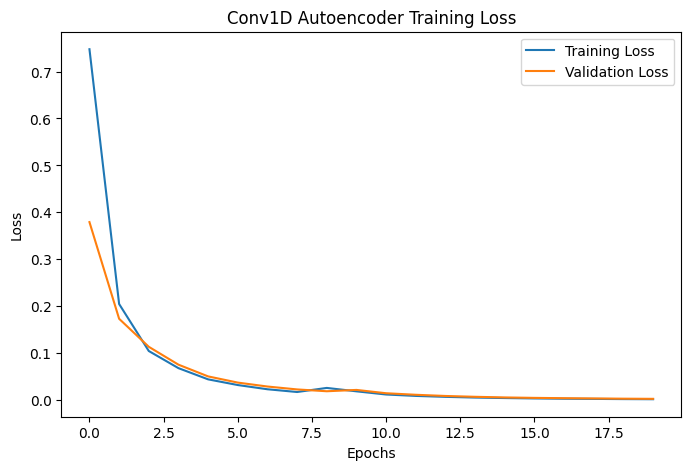

In [10]:
# =====================================================
# STEP 10: PLOT TRAINING AND VALIDATION LOSS
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Conv1D Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

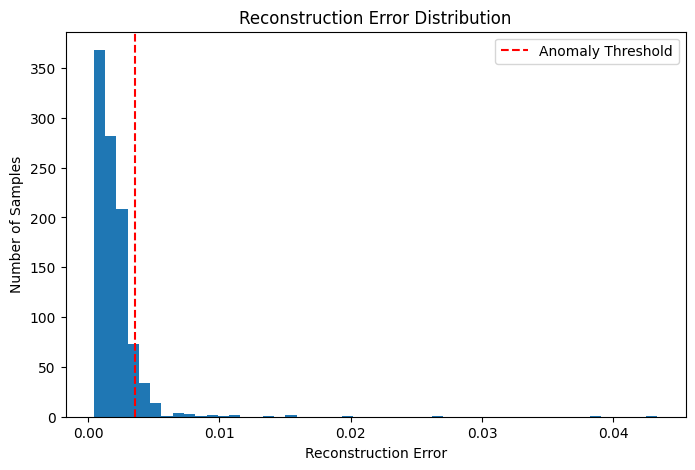

In [11]:
# =====================================================
# STEP 11: PLOT RECONSTRUCTION ERROR
# =====================================================

plt.figure(figsize=(8, 5))

plt.hist(test_error, bins=50)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title('Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Samples')
plt.legend()
plt.show()
